In [34]:
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations

In [35]:
# Load Datsets
def load_images(class_folder, img_size=(64, 64)):
    X = []

    for file in os.listdir(class_folder):
        img_path = os.path.join(class_folder, file)

        # Read image (RGB)
        img = cv2.imread(img_path) 

        if img is None:
            continue  # skip corrupted files

        # Resize -> not necessary for ORB/SIFT but more robust+faster processing
        #img = cv2.resize(img, img_size) # Resizing led to worse quality images with fewer keypoints

        X.append(img)

    return X

In [36]:
X_train = load_images("Datasets/dataset_1/group_5-15")

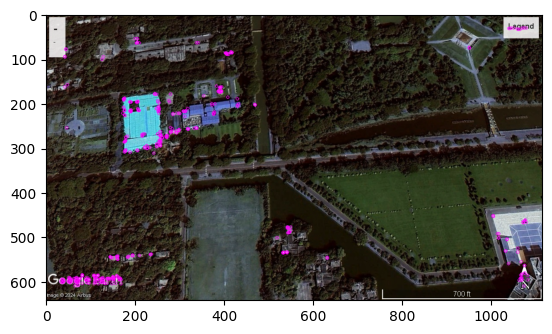

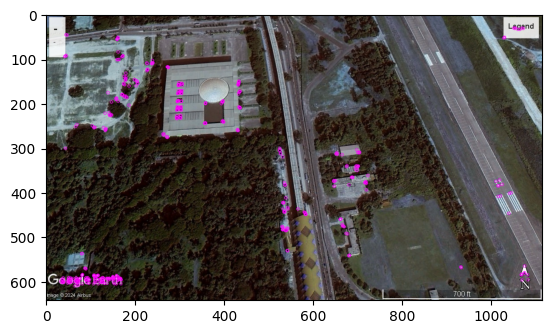

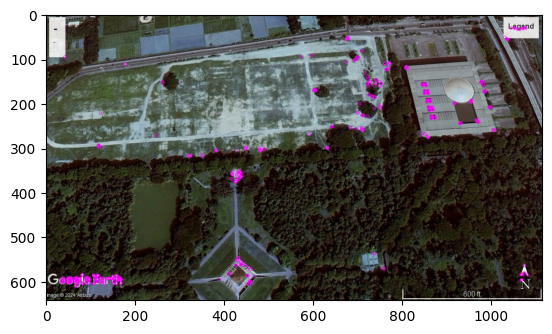

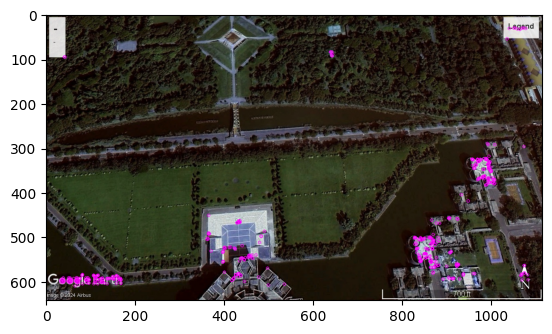

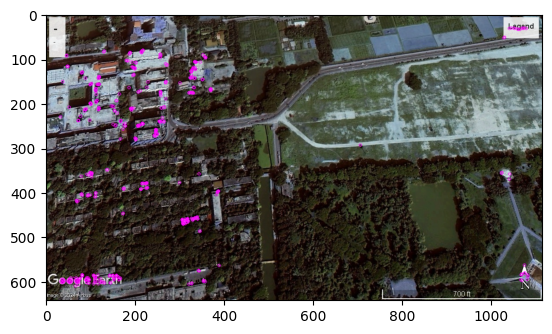

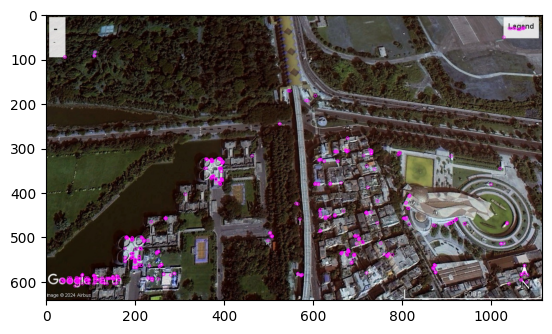

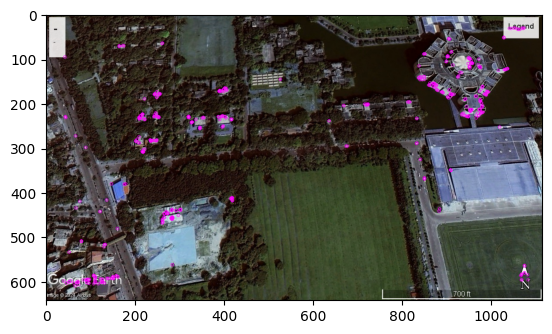

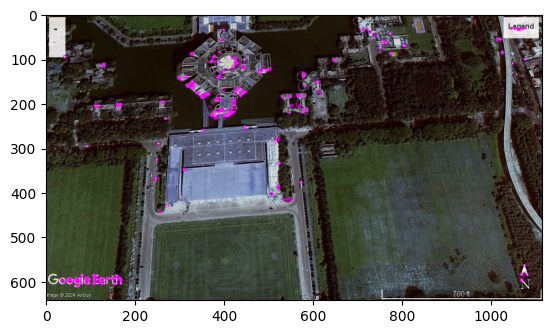

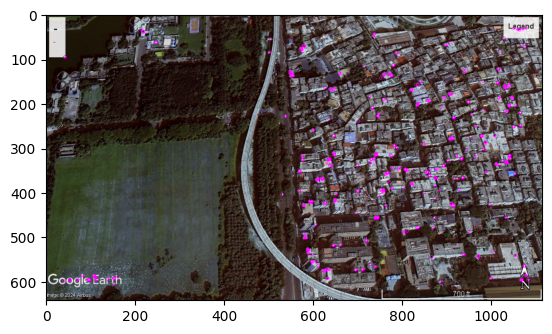

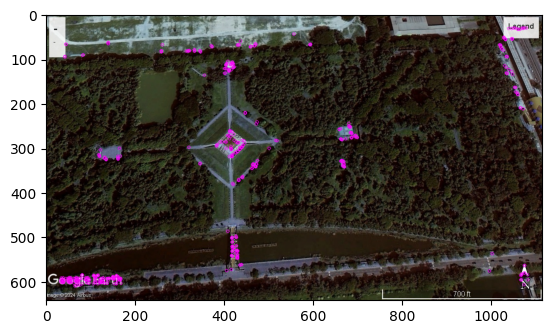

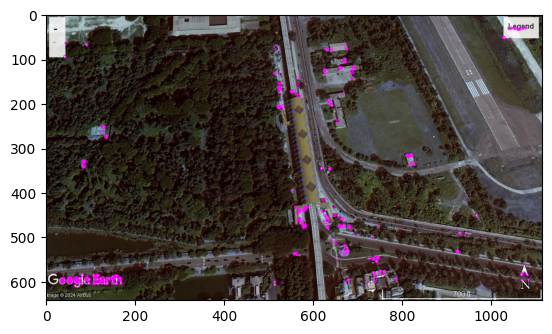

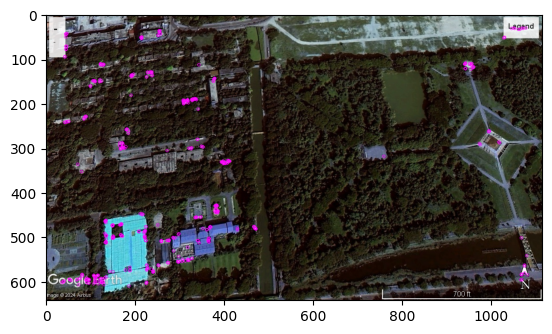

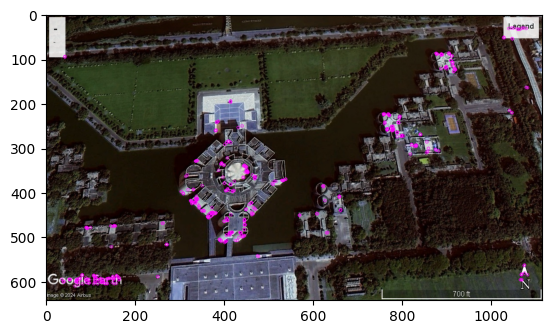

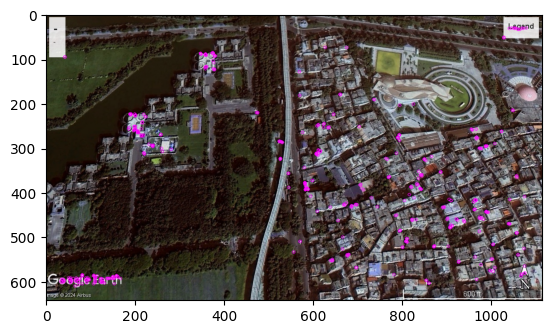

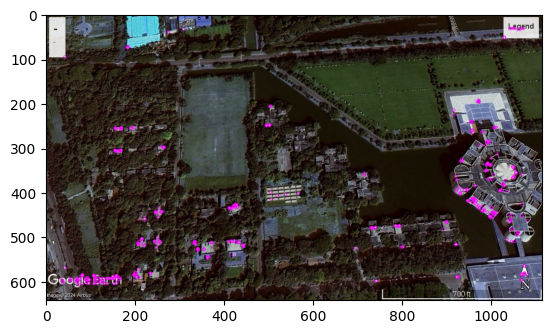

In [37]:
# Extract local features from every image - ORB

features = []
orb = cv2.ORB_create()

for img in X_train:

    kp = orb.detect(img,None)
    kp, des = orb.compute(img, kp)
    features.append((kp, des))

    img2 = cv2.drawKeypoints(img, kp, None, color=(255,0,255), flags=0)
    plt.imshow(img2), plt.show()

In [43]:
# Match features between all image pairs + Lowe's ratio test to remove false/ambigious matches

bf = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=False)

for i, j in combinations(range(len(X_train)), 2):
    img1, (kp1, des1) = X_train[i], features[i]
    img2, (kp2, des2) = X_train[j], features[j]
    
    # Skip if one image has no descriptors
    if des1 is None or des2 is None:
        continue

    # Use knnMatch to find the two best matches for each descriptor
    matches = bf.knnMatch(des1, des2, k=2)  # k=2 to get the two best matches

    # Apply Lowe's Ratio Test to filter out ambiguous matches
    matches_with_ratio = []
    for m, n in matches:
        if m.distance < 0.8 * n.distance:  # Lowe's ratio test
            matches_with_ratio.append(m)

    # Draw and display the top 10 matches
    img_matches = cv2.drawMatches(
        img1, kp1, img2, kp2, matches_with_ratio[:10], None, 
        matchColor=(255, 0, 255), # Dark Green
        flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS
    )

    #plt.figure(figsize=(12, 6))
    #plt.imshow(img_matches)
    #plt.title(f"Matches between Image {i} and Image {j}")
    #plt.show()

print(len(matches))
print(len(matches_with_ratio))

500
31


In [ ]:
# Build a similarity graph


In [ ]:
# Cluster the graph


In [ ]:
# Detect keypoints (ORB/SIFT) + match descriptors + RANSAC + warp images + blend


In [ ]:
# Convert to 2D map


In [ ]:
# Road segmentation


In [ ]:
# Shortest Path (Djikstra or A*)
